In [12]:
import pandas as pd
import matplotlib.pyplot as plt
print("Librairies loaded succesfully")

Librairies loaded succesfully


In [20]:
df = pd.read_csv("dhl_shipments_dashboard.csv")
print("Total shipments", len(df))
print("Total columns", len(df.columns))
print(df["delivery_status"].value_counts())
print(df["shipping_method"].value_counts())

Total shipments 15000
Total columns 12
delivery_status
On Time         12259
Late             2348
Invalid Date      393
Name: count, dtype: int64
shipping_method
Ground      9702
Express     3831
Next Day    1467
Name: count, dtype: int64


In [22]:
total_shipments = len(df)
print(total_shipments)

15000


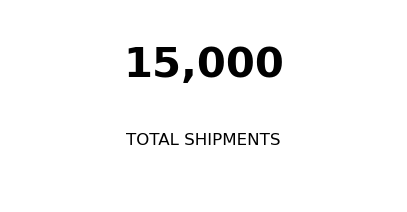

In [25]:
fig, ax = plt.subplots(figsize = (5,2.5))
ax.text(0.5,0.65, f"{total_shipments:,}", fontsize = 30, fontweight = "bold", ha = "center")
ax.text (0.5, 0.30, "TOTAL SHIPMENTS", fontsize = 12, ha = "center")
ax.axis("off")
plt.show()

In [33]:
On_time_shipments = (df["delivery_status"] == "On Time").sum()
Valid_shipments = (df["delivery_status"].isin(["On Time", "Late"]).sum())
On_time_rate = (On_time_shipments / Valid_shipments) * 100
print("On time shipments", On_time_shipments)
print("Valid shipments", Valid_shipments)
print("On time rate",round(On_time_rate,2), "%")

On time shipments 12259
Valid shipments 14607
On time rate 83.93 %


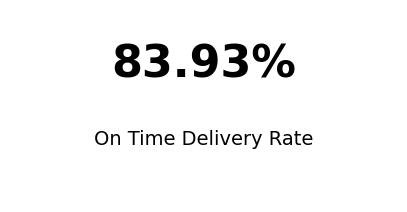

In [34]:
fig, ax = plt.subplots(figsize = (5,2.5))
ax.text(0.5, 0.65, f"{On_time_rate:.2f}%", fontsize = 32, fontweight = "bold", ha = "center")
ax.text(0.5, 0.30, "On Time Delivery Rate", fontsize = 14, ha = "center")
ax.axis("off")
plt.show()

In [35]:
invalid_shipments = (df["delivery_status"] == "Invalid Date").sum()
print("Invalid Delivery Dates:", invalid_shipments)

Invalid Delivery Dates: 393


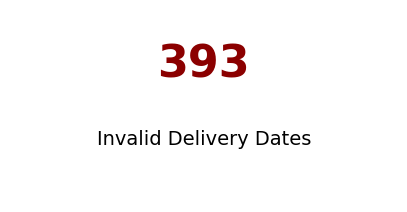

In [38]:
fig, ax = plt.subplots(figsize = (5,2.5))
ax.text(0.5, 0.65, f"{invalid_shipments:,}", fontsize = 32, fontweight = "bold", color = "darkred", ha = "center")
ax.text(0.5, 0.30, "Invalid Delivery Dates", fontsize = 14, ha = "center")
ax.axis("off")
plt.show()

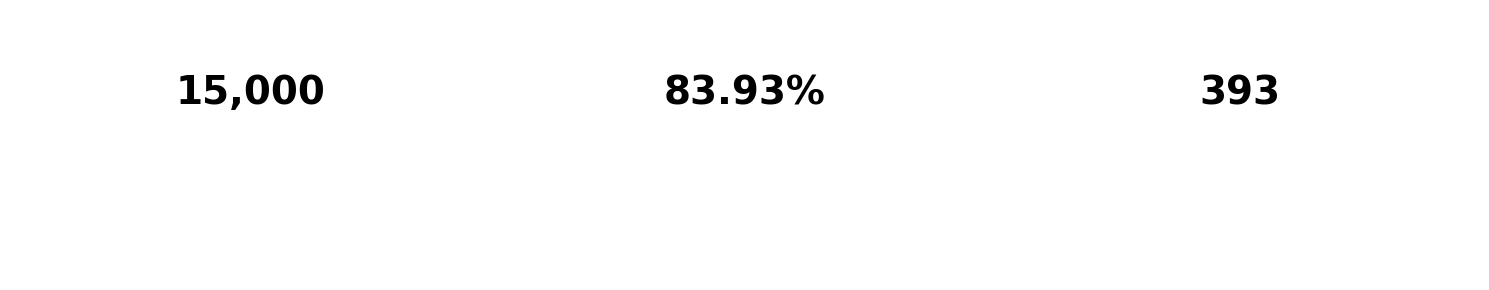

In [47]:
fig, axes = plt.subplots(1, 3, figsize = (15, 3))
kpis = [ 
    ("TOTAL SHIPMENTS", f"{total_shipments:,}"),
    ("ON TIME DELIVERY RATE", f"{On_time_rate:.2f}%"),
    ("INVALID DELIVERY DATES", f"{invalid_shipments:,}")
     ]
for ax, (label, value) in zip(axes, kpis):
    ax.text(0.5, 0.65, value, fontsize = 28, fontweight = "bold", ha = "center")
    ax.axis("off")
plt.tight_layout()
plt.show()
                                          

In [48]:
valid_df = df[df["delivery_status"].isin(["On Time", "Late"])]
print("Valid shipments:", len(valid_df))

Valid shipments: 14607


In [49]:
center_performance = (valid_df.groupby("center_id")["delivery_status"].apply(lambda x: (x == "On Time").mean() * 100).round(2).sort_values())
print(center_performance)

center_id
ATL    75.74
EWR    77.45
LAX    85.21
DFW    85.49
BOS    86.44
ORD    86.61
DEN    87.00
SEA    87.74
Name: delivery_status, dtype: float64


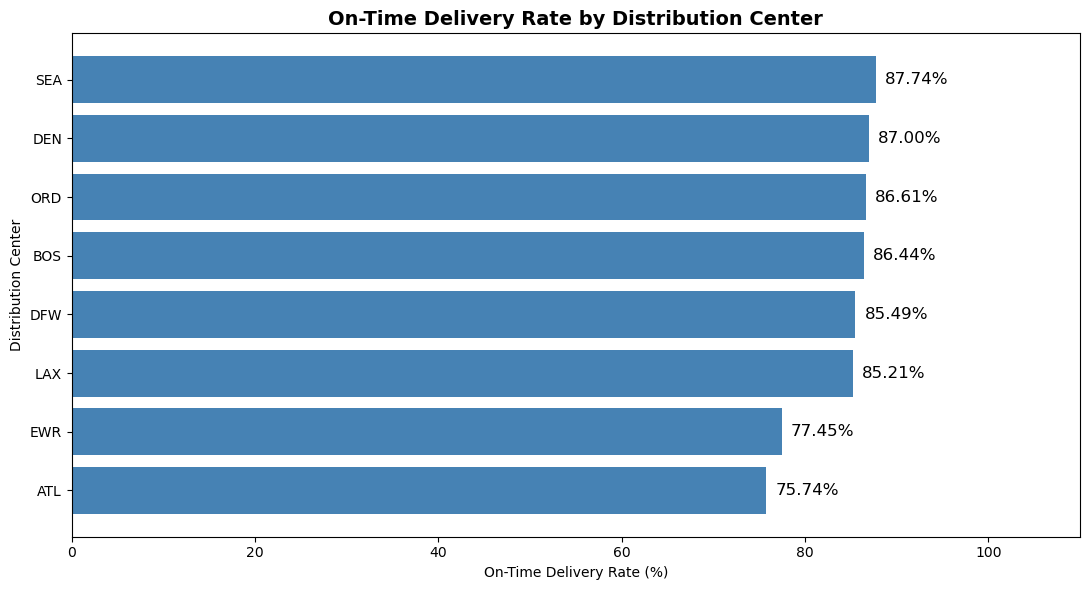

In [62]:
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    center_performance.index,
    center_performance.values,
    color="steelblue"
)

ax.set_title(
    "On-Time Delivery Rate by Distribution Center",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("On-Time Delivery Rate (%)")
ax.set_ylabel("Distribution Center")

ax.set_xlim(0, 110)

# Add percentage labels to every bar
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center",
        fontsize=12,
        color="black"
    )

plt.tight_layout()
plt.show()

In [64]:
center_transport_cost = (df.groupby("center_id")["transport_cost_usd"].mean().round(2).sort_values())
print(center_transport_cost)

center_id
BOS    78.45
EWR    79.32
ORD    79.32
DEN    79.67
SEA    80.03
DFW    80.44
LAX    80.71
ATL    82.01
Name: transport_cost_usd, dtype: float64


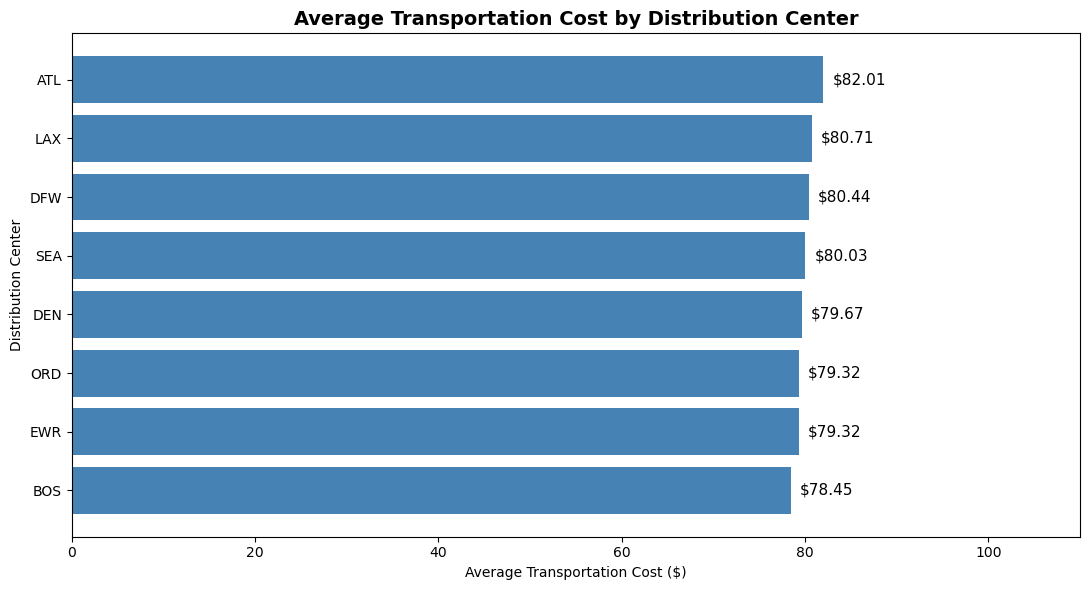

In [72]:
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    center_transport_cost.index,
    center_transport_cost.values,
    color="steelblue"
)

ax.set_title(
    "Average Transportation Cost by Distribution Center",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Average Transportation Cost ($)")
ax.set_ylabel("Distribution Center")

# Give the dollar labels extra room
ax.set_xlim(0, 110)

# Add a dollar label to every bar
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f"${width:.2f}",
        va="center",
        fontsize=11,
        color="black"
    )

plt.tight_layout()
plt.show()

In [ ]:
## Average Tranportation cost by shipping method


In [74]:
shipping_cost = (df.groupby("shipping_method")["transport_cost_usd"].mean().round(2).sort_values())
print(shipping_cost)

shipping_method
Ground       71.66
Express      90.71
Next Day    107.25
Name: transport_cost_usd, dtype: float64


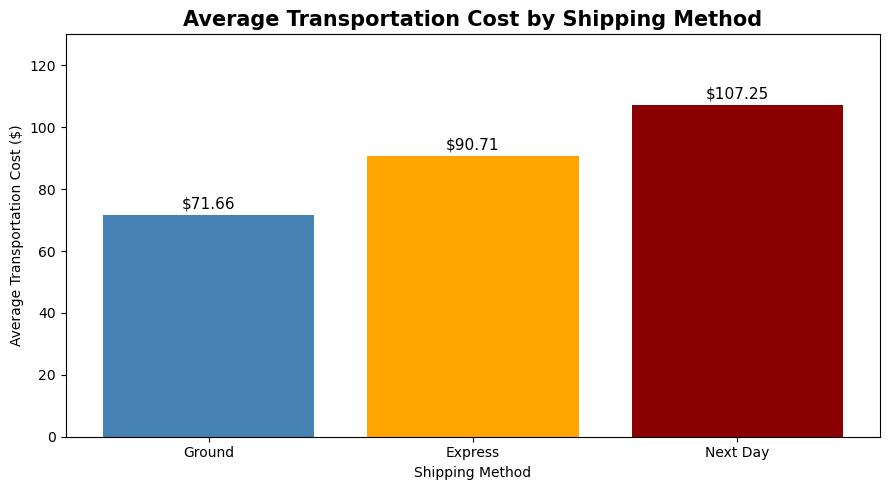

In [75]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    shipping_cost.index,
    shipping_cost.values,
    color=["steelblue", "orange", "darkred"]
)

ax.set_title(
    "Average Transportation Cost by Shipping Method",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Shipping Method")
ax.set_ylabel("Average Transportation Cost ($)")
ax.set_ylim(0, 130)

# Add dollar labels above each bar
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f"${height:.2f}",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

In [77]:
shipping_performance = (valid_df.groupby("shipping_method")["delivery_status"].apply(lambda x: (x == "On Time").mean() * 100).round(2).sort_values(ascending = False))
print(shipping_performance)

shipping_method
Ground      84.52
Express     83.74
Next Day    79.24
Name: delivery_status, dtype: float64


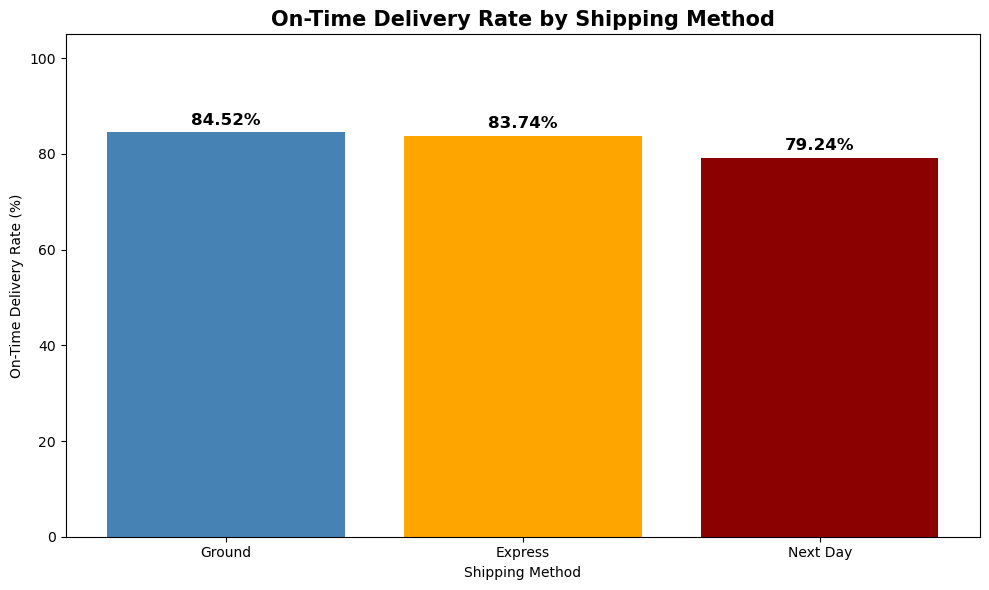

In [78]:
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    shipping_performance.index,
    shipping_performance.values,
    color=["steelblue", "orange", "darkred"]
)

ax.set_title(
    "On-Time Delivery Rate by Shipping Method",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Shipping Method")
ax.set_ylabel("On-Time Delivery Rate (%)")

# Give the labels room above the bars
ax.set_ylim(0, 105)

# Display percentages above every bar
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

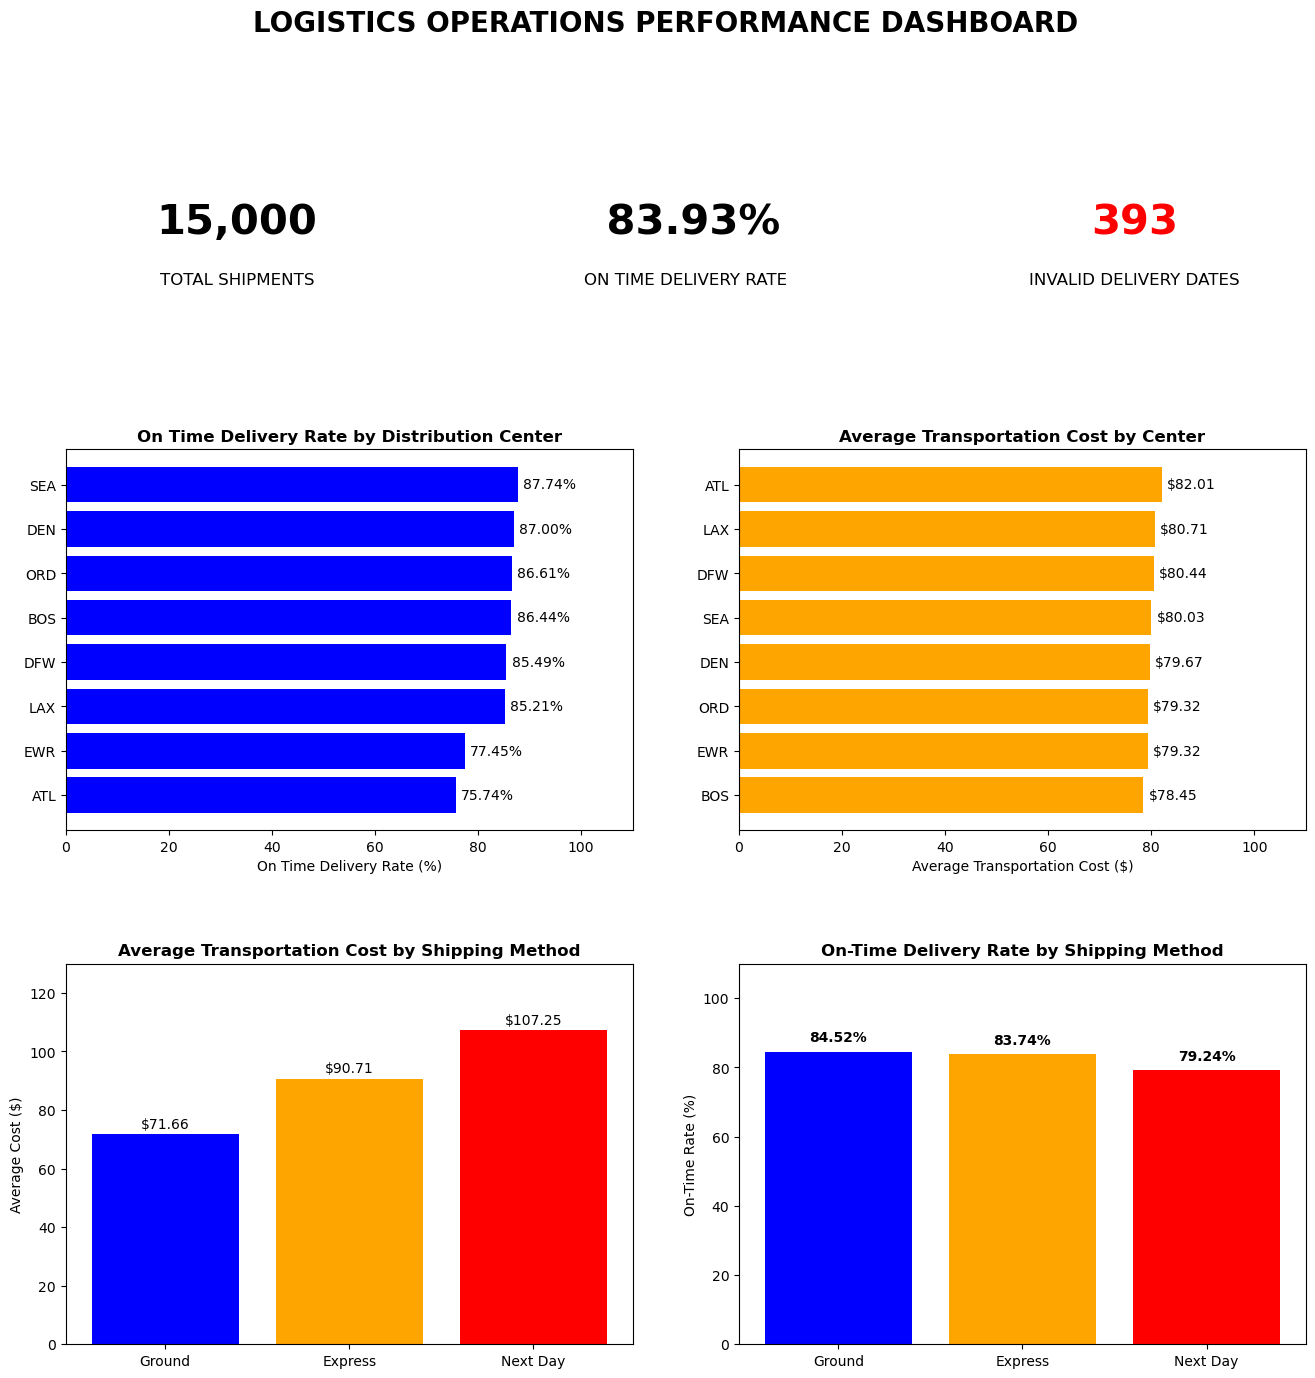

In [113]:
fig = plt.figure(figsize = (16,15))
fig.suptitle("LOGISTICS OPERATIONS PERFORMANCE DASHBOARD", fontsize = 20, fontweight = "bold", y = 1)
gs = fig.add_gridspec(3, 6, height_ratios = [1, 3, 3], hspace = 0.45, wspace = 0.9)

## total shipments

ax1 = fig.add_subplot(gs[0, 0:2])
ax1.text(0.5, 0.65, f"{total_shipments:,}", fontsize = 30, fontweight = "bold", ha = "center")
ax1.text(0.5, 0.25, "TOTAL SHIPMENTS", fontsize = 12, ha = "center")
ax1.axis("off")

## on time delivery rate 
ax2 = fig.add_subplot(gs[0, 2:4])
ax2.text(0.5, 0.65, f"{On_time_rate: .2f}%", fontsize = 30, fontweight = "bold", ha = "center")
ax2.text(0.5, 0.25, "ON TIME DELIVERY RATE", fontsize = 12, ha = "center")
ax2.axis("off")


## Invalid delivery dates
ax3 = fig.add_subplot(gs[0, 4:6])
ax3.text(0.5, 0.65, f"{invalid_shipments:,}", fontsize = 30, fontweight = "bold", color = "red", ha = "center")
ax3.text(0.5, 0.25, "INVALID DELIVERY DATES", fontsize = 12, ha = "center")
ax3.axis("off")


## on time delivery rate by distribution center.
ax4 = fig.add_subplot(gs[1, 0:3])
bars = ax4.barh(center_performance.index, center_performance.values, color = "blue")
ax4.set_title( "On Time Delivery Rate by Distribution Center", fontsize = 12, fontweight = "bold")
ax4.set_xlabel("On Time Delivery Rate (%)")
ax4.set_xlim(0, 110)
for bar in bars:
    width = bar.get_width()
    ax4.text(width + 1, bar. get_y() + bar.get_height() / 2, f"{width:.2f}%", va = "center", fontsize = 10) 



### average transportation cost by distribution center
ax5 = fig.add_subplot(gs[1, 3:6])

bars = ax5.barh(center_transport_cost.index, center_transport_cost.values, color= "orange")

ax5.set_title("Average Transportation Cost by Center", fontsize = 12, fontweight = "bold")

ax5.set_xlabel("Average Transportation Cost ($)")
ax5.set_xlim(0, 110)

for bar in bars:
    width = bar.get_width()
    ax5.text(width + 1, bar.get_y() + bar.get_height() / 2, f"${width:.2f}", va = "center", fontsize = 10 )


### average transportaiton cost by shipping method
ax6 = fig.add_subplot(gs[2, 0:3])

bars = ax6.bar(shipping_cost.index, shipping_cost.values, color=["blue", "orange", "red"])

ax6.set_title("Average Transportation Cost by Shipping Method", fontsize=12, fontweight="bold")

ax6.set_ylabel("Average Cost ($)")
ax6.set_ylim(0, 130)

for bar in bars:
    height = bar.get_height()
    ax6.text(bar.get_x() + bar.get_width() / 2, height + 2, f"${height:.2f}", ha = "center", fontsize = 10)


### on time delivery rate by shipping method 

ax7 = fig.add_subplot(gs[2, 3:6])

bars = ax7.bar(shipping_performance.index, shipping_performance.values, color=["blue", "orange", "red"])

ax7.set_title(
    "On-Time Delivery Rate by Shipping Method", fontsize=12, fontweight="bold")
ax7.set_ylabel("On-Time Rate (%)")

# Make room for all percentage labels
ax7.set_ylim(0, 110)

# Add percentage labels to every bar
for bar in bars:
    height = bar.get_height()
    ax7.annotate(f"{height:.2f}%", xy = (bar.get_x() + bar.get_width() / 2, height), xytext=(0, 5), textcoords = "offset points", ha = "center", va = "bottom", fontsize=10, fontweight="bold", color="black")